# 3.9.3 조건 변경 참고 실습

A·B·C·D 노드와 간선 비용을 코드에 직접 정의합니다. 두 경로의 비용 6과 4를 손으로 검산하기 쉬워 선택했습니다.

선정 이유: 기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 heapq 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 heapq 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import heapq

## 셀 2 입력·계산·출력 확인

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.

In [2]:
# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),
    "svg.fonttype":"none", "figure.figsize":(7.0,4.2)})

# 현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
CHAPTER = HERE if (HERE / "data").exists() else HERE.parent

# 입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
DATA = CHAPTER / "data"

# 결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
OUT = HERE / "results" / "task01_reference"

# 앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
OUT.mkdir(parents=True, exist_ok=True)

# 검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.
assert DATA.exists(), f"장별 data 폴더가 없습니다: {DATA}. 저장소 전체를 내려받으세요."

## 셀 3 함수와 모듈 정의

현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.

In [3]:
# 현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.
def figure(out, name):
    # 실제 현재 그림을 벡터와 300dpi 흑백 삽입본으로 저장합니다.
    plt.tight_layout()
    plt.savefig(out / (name + ".svg"), facecolor="white")
    plt.savefig(out / (name + ".png"), dpi=300, facecolor="white")
    if "get_ipython" in globals():
        display(NotebookImage(filename=str(out / (name + ".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.

In [4]:
# 계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.
def report(out, name, metrics):
    # 계산된 값만 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
    text = json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False)
    (out / (name + ".json")).write_text(text, encoding="utf-8")
    print(text)

## 셀 5 함수와 모듈 정의

가장 작은 예상 비용의 상태를 먼저 꺼내 최단 경로를 탐색합니다. 목적지 도달과 더 나쁜 중복 상태의 제외 조건을 구분합니다.

In [5]:
# 가장 작은 예상 비용의 상태를 먼저 꺼내 최단 경로를 탐색합니다. 목적지 도달과 더 나쁜 중복 상태의 제외 조건을 구분합니다.
def a_star_search(graph, heuristics, start, goal):
    queue = [(heuristics[start], 0, start, [start])]
    best_cost = {start: 0}
    while queue:
        estimated_cost, cost, current, path = heapq.heappop(queue)
        if current == goal:
            return path, cost
        if cost > best_cost.get(current, float("inf")):
            continue
        for neighbor, weight in graph.get(current, []):
            new_cost = cost + weight
            if new_cost < best_cost.get(neighbor, float("inf")):
                best_cost[neighbor] = new_cost
                priority = new_cost + heuristics[neighbor]
                heapq.heappush(queue, (priority, new_cost, neighbor, path + [neighbor]))
    return None, float("inf")

## 셀 6 입력·계산·출력 확인

가중 방향 그래프(Weighted Directed Graph, graph)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

휴리스틱 추정 비용(Heuristic Cost Estimates, heuristics)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

경로(Path, path)·비용(Cost, cost)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

변수 pos를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

변수 fig·변수 ax를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

반복 조건 for node,(x,y) in pos.items():에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.

반복 조건 for a,edges in graph.items():에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.

계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.

최적 경로: ['A', 'C', 'D'] | 총 비용: 2
{
  "path": [
    "A",
    "C",
    "D"
  ],
  "cost": 2
}


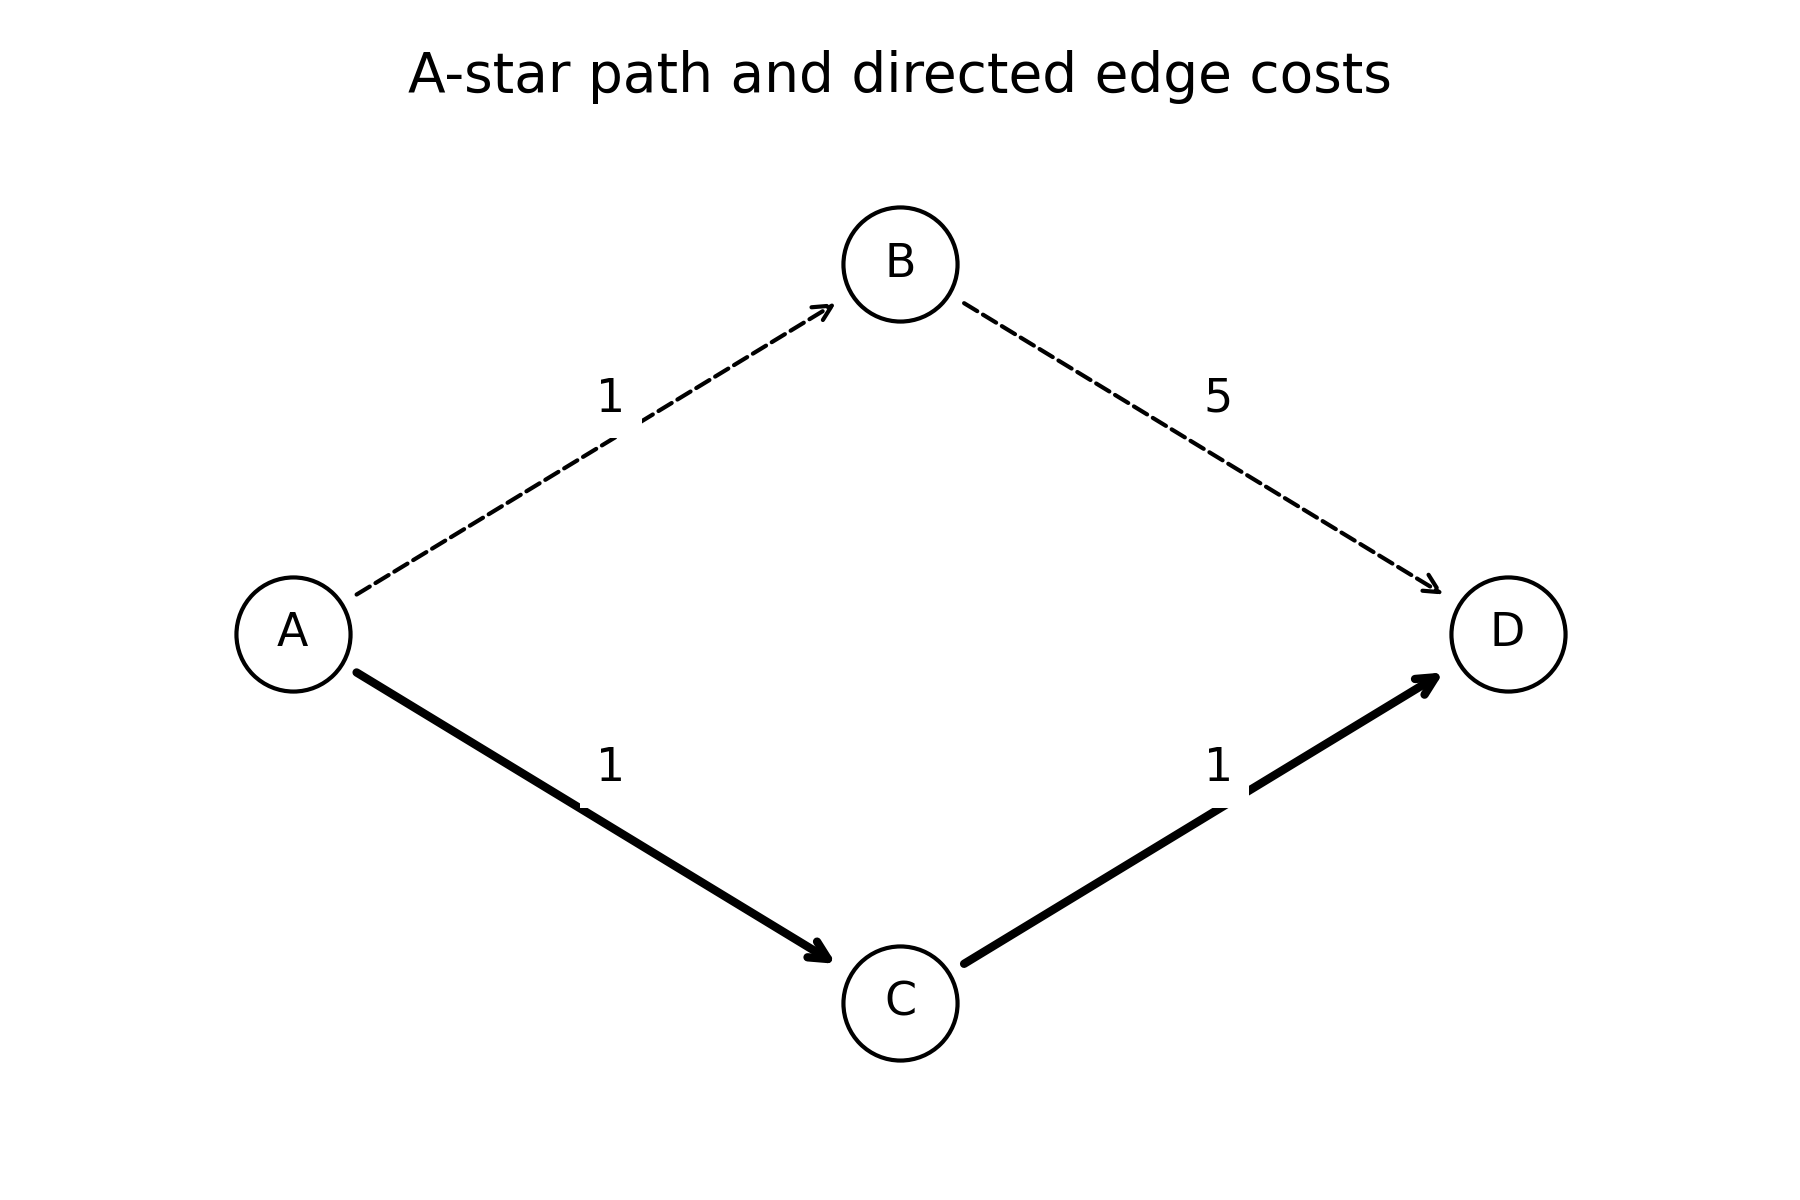

In [6]:
# 가중 방향 그래프(Weighted Directed Graph, graph)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
graph = {"A": [("B", 1), ("C", 1)], "B": [("D", 5)], "C": [("D", 1)], "D": []}

# 휴리스틱 추정 비용(Heuristic Cost Estimates, heuristics)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
heuristics = {"A": 4, "B": 2, "C": 1, "D": 0}

# 경로(Path, path)·비용(Cost, cost)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
path, cost = a_star_search(graph, heuristics, "A", "D")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"최적 경로: {path} | 총 비용: {cost}")

# 변수 pos를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
pos={"A":(0,1),"B":(1,2),"C":(1,0),"D":(2,1)}

# 변수 fig·변수 ax를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
fig,ax=plt.subplots(figsize=(6,4))

# 반복 조건 for node,(x,y) in pos.items():에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.
for node,(x,y) in pos.items():
    ax.scatter([x],[y],s=750,facecolors="white",edgecolors="black",zorder=3);ax.text(x,y,node,ha="center",va="center",zorder=4)

# 반복 조건 for a,edges in graph.items():에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.
for a,edges in graph.items():
    for b,w in edges:
        x,y=pos[a];u,v=pos[b];chosen=(a,b) in list(zip(path,path[1:]))
        ax.annotate("",xy=(u,v),xytext=(x,y),arrowprops=dict(arrowstyle="->",color="black",lw=2 if chosen else 1,linestyle="-" if chosen else "--",shrinkA=18,shrinkB=18))
        ax.text((x+u)/2,(y+v)/2+0.1,str(w),bbox=dict(facecolor="white",edgecolor="none"))

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
ax.set(xlim=(-.4,2.4),ylim=(-.4,2.4),title="A-star path and directed edge costs")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
ax.axis("off")

# 실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.
figure(OUT,"astar_path")

# 계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.
report(OUT,"summary",{"path":path,"cost":cost})

## 그림과 결과 해석

기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다. 굵은 경로의 간선 비용을 합해 출력 비용과 비교합니다. 그림의 직선 길이는 코드 비용이 아닙니다.